# Kasus 03 · Sisa Umur Pakai (RUL) Motor Induksi

**Klien:** manajer pemeliharaan grup pabrik (Cikarang, Karawang, Purwakarta).
**Pertanyaan klien:** "Berapa hari lagi motor ini masih bisa bekerja?" Motor pengganti butuh 2–4 minggu
pengiriman, jadi pesanan harus dibuat sebelum motor lama rusak.

**Tugas:** regresi, menebak `rul_hari` dari pembacaan sensor satu hari.
**Metrik utama:** MAE pada baris dengan `rul_hari` ≤ 60. **Baseline wajib:** regresi linear dengan sensor asli.

Alur notebook (think → act → ship):

1. Memahami data mentah
2. Memeriksa masalah data
3. Membersihkan data
4. Membagi data **per motor**
5. EDA (hanya data train)
6. Baseline wajib
7. Model lain dan perbandingan pada data validation
8. Memilih model final dan ambang status
9. Eksperimen tambahan: memakai riwayat beberapa hari
10. Model final dan data test (dibuka satu kali)
11. Menyimpan artifact

In [1]:
import json
import platform
import sys
import warnings
from datetime import date
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

# notebook ada di folder notebooks/, sedangkan src/ dan data/ ada di root repositori
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.features import (FITUR_INPUT, FITUR_MODEL, KOEF_GETARAN, KOEF_RPM, KOEF_SUHU, KOLOM_SENSOR, TARGET,
                          bersihkan_data, rapikan_tipe, sensor_asli, tambah_fitur)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

SEED = 42                 # supaya hasil sama setiap dijalankan ulang
BATAS_DEKAT_RUSAK = 60    # metrik utama dihitung pada baris dengan RUL <= 60 hari
GAMBAR = ROOT / "laporan" / "gambar"
GAMBAR.mkdir(parents=True, exist_ok=True)

# gaya grafik: garis tipis, kisi samar, warna yang tetap terbedakan oleh penyandang buta warna
BIRU, ORANYE, HIJAU, ABU = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
TINTA = "#52514e"
BIRU_BERTINGKAT = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": ABU,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.labelcolor": TINTA, "xtick.color": TINTA, "ytick.color": TINTA,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "legend.frameon": False,
})

## 1. Memahami data mentah

In [2]:
mentah = pd.read_csv(ROOT / "data" / "raw.csv")
print("ukuran:", mentah.shape)
mentah.head()

ukuran: (79652, 11)


,motor_id,tipe_motor,lokasi,hari_operasi,beban_pct,arus_A,tegangan_V,suhu_belitan_C,getaran_rms_mm_s,kecepatan_rpm,rul_hari
0,M-001,5.5kW,Plant Purwakarta,0,95.4,10.47,376.5,337.2,2.08,1472.0,251
1,M-001,5.5kW,Plant Purwakarta,1,82.1,8.81,382.0,332.8,2.14,1476.0,250
2,M-001,5.5kW,Plant Purwakarta,2,82.3,8.74,383.8,328.0,2.00,1474.0,249
3,M-001,5.5kW,Plant Purwakarta,3,80.7,8.42,377.0,333.3,2.03,1476.0,248
4,M-001,5.5kW,Plant Purwakarta,4,89.3,9.46,384.5,333.2,2.06,1477.0,247


In [3]:
mentah.info()

<class 'pandas.DataFrame'>
RangeIndex: 79652 entries, 0 to 79651
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   motor_id          79652 non-null  str    
 1   tipe_motor        79652 non-null  str    
 2   lokasi            79652 non-null  str    
 3   hari_operasi      79652 non-null  int64  
 4   beban_pct         79652 non-null  float64
 5   arus_A            78050 non-null  float64
 6   tegangan_V        79652 non-null  float64
 7   suhu_belitan_C    78858 non-null  float64
 8   getaran_rms_mm_s  79652 non-null  float64
 9   kecepatan_rpm     79652 non-null  float64
 10  rul_hari          79652 non-null  int64  
dtypes: float64(6), int64(2), str(3)
memory usage: 8.5 MB


In [4]:
mentah.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
hari_operasi,79652.0,149.77,102.89,0.00,67.00,135.00,216.00,543.00
beban_pct,79652.0,74.69,12.44,38.90,64.90,74.40,84.40,110.00
arus_A,78050.0,15.95,8.75,4.13,8.78,14.22,19.31,47.24
tegangan_V,79652.0,380.00,4.00,363.40,377.30,380.00,382.70,396.80
suhu_belitan_C,78858.0,153.04,127.74,39.60,61.40,70.60,330.80,372.00
getaran_rms_mm_s,79652.0,3.00,1.43,-1.00,2.06,2.35,3.48,8.01
kecepatan_rpm,79652.0,1470.67,5.85,1451.00,1467.00,1472.00,1475.00,1485.00
rul_hari,79652.0,149.74,102.93,0.00,66.00,135.00,217.00,543.00


Dari ringkasan di atas sudah terlihat beberapa hal yang janggal: `arus_A` dan `suhu_belitan_C` tidak lengkap,
`suhu_belitan_C` punya rata-rata 153 °C dengan nilai maksimum 372 °C (belitan motor biasanya di bawah 150 °C),
dan `getaran_rms_mm_s` punya nilai minimum −1 (getaran RMS tidak mungkin negatif).
Brief juga sudah mengingatkan bahwa data belum diperiksa siapa pun. Bagian berikut memeriksanya satu per satu.

## 2. Memeriksa masalah data

### 2.1 Penulisan `motor_id` tidak seragam
Brief menyebut 300 motor, tetapi jumlah ID uniknya jauh lebih banyak.

In [5]:
print("jumlah motor_id unik (mentah):", mentah["motor_id"].nunique())
id_baku = mentah["motor_id"].str.fullmatch(r"M-\d{3}")
print("baris dengan ID tidak baku   :", int((~id_baku).sum()))
print("contoh ID tidak baku         :", mentah.loc[~id_baku, "motor_id"].unique()[:9].tolist())

nomor = mentah["motor_id"].str.extract(r"(\d+)")[0].astype(int)
id_rapi = "M-" + nomor.astype(str).str.zfill(3)
print("jumlah motor setelah dirapikan:", id_rapi.nunique())

jumlah motor_id unik (mentah): 1147
baris dengan ID tidak baku   : 3185
contoh ID tidak baku         : ['m-001', 'M001', 'M-001 ', 'M-002 ', 'M002', 'm-002', 'M003', 'M-003 ', 'm-003']
jumlah motor setelah dirapikan: 300


Ada tiga variasi salah tulis (`m-001`, `M001`, dan `M-001 ` dengan spasi di belakang). Setelah angkanya diambil
dan ditulis ulang, jumlah motor menjadi tepat 300.

**Mengapa ini penting sekali:** pembagian data dilakukan per `motor_id`. Kalau `m-001` dan `M-001` dianggap dua
motor berbeda, motor yang sama bisa masuk ke train dan test sekaligus dan aturan brief terlanggar tanpa disadari.

### 2.2 Penulisan `tipe_motor` tidak seragam dan tidak konsisten

In [6]:
print(mentah["tipe_motor"].value_counts())
tipe_rapi = rapikan_tipe(mentah["tipe_motor"])
print("\nbaris dengan penulisan tipe tidak baku:", int((mentah["tipe_motor"] != tipe_rapi).sum()))

# berapa macam tipe yang tercatat untuk satu motor? (seharusnya 1)
macam_tipe = tipe_rapi.groupby(id_rapi).nunique()
print("\njumlah tipe berbeda per motor -> jumlah motor:")
print(macam_tipe.value_counts().sort_index())

tipe_mayoritas = tipe_rapi.groupby(id_rapi).transform(lambda s: s.mode().iloc[0])
print("\nbaris yang tipenya berbeda dari tipe mayoritas motornya:", int((tipe_rapi != tipe_mayoritas).sum()))

tipe_motor
11kW      35041
5.5kW     29211
22kW      13812
22KW        549
11 kW       533
5,5 kW      506
Name: count, dtype: int64

baris dengan penulisan tipe tidak baku: 1588

jumlah tipe berbeda per motor -> jumlah motor:
tipe_motor
1     19
2     81
3    200
Name: count, dtype: int64

baris yang tipenya berbeda dari tipe mayoritas motornya: 1045


Merapikan tulisan saja belum cukup. Sebagian besar motor tercatat memiliki 2–3 tipe berbeda, padahal daya
nominal motor tidak mungkin berubah. Baris yang salah itu justru baris dengan penulisan tidak baku
(`22KW`, `11 kW`, `5,5 kW`), jadi tipenya salah input. Arus pada baris tersebut tetap mengikuti tipe mayoritas
motornya (dicek di bawah), sehingga perbaikannya adalah **memakai tipe yang paling sering muncul pada motor itu**.

In [7]:
cek = pd.DataFrame({"tipe_tercatat": tipe_rapi, "tipe_mayoritas": tipe_mayoritas, "arus_A": mentah["arus_A"]})
salah = cek[cek["tipe_tercatat"] != cek["tipe_mayoritas"]]
print("median arus (A) pada baris yang tipenya tidak cocok:")
print(salah.groupby(["tipe_mayoritas", "tipe_tercatat"])["arus_A"].median().unstack().round(1))
print("\nmedian arus (A) normal per tipe:")
print(cek[cek["tipe_tercatat"] == cek["tipe_mayoritas"]].groupby("tipe_mayoritas")["arus_A"].median().round(1))

median arus (A) pada baris yang tipenya tidak cocok:
tipe_tercatat   11kW  22kW  5.5kW
tipe_mayoritas                   
11kW             NaN  16.2   16.3
22kW            32.0   NaN   30.4
5.5kW            8.2   8.0    NaN

median arus (A) normal per tipe:
tipe_mayoritas
11kW     16.2
22kW     31.7
5.5kW     8.1
Name: arus_A, dtype: float64


### 2.3 Baris kembar

In [8]:
kunci = pd.DataFrame({"motor_id": id_rapi, "hari_operasi": mentah["hari_operasi"]})
print("baris kembar persis (semua kolom sama):", int(mentah.duplicated().sum()))
print("motor + hari yang tercatat lebih dari sekali:", int(kunci.duplicated().sum()))

baris kembar persis (semua kolom sama): 493
motor + hari yang tercatat lebih dari sekali: 493


Satu motor pada satu hari seharusnya satu baris. Baris kembar dihapus dan disisakan satu.

### 2.4 Satuan suhu belitan tercampur (°C dan kelvin)

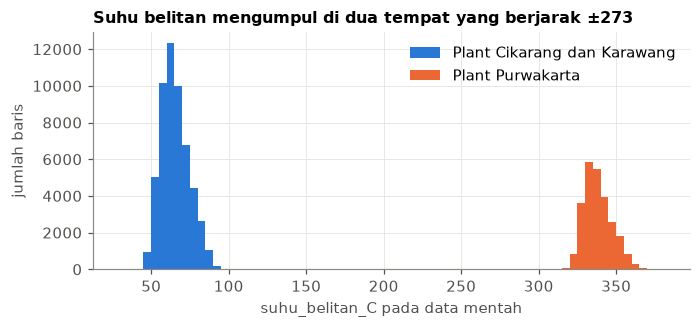

                    count    min    50%    max
lokasi                                        
Plant Cikarang    29496.0   39.6   63.7   98.7
Plant Karawang    24007.0   42.1   64.9   98.5
Plant Purwakarta  25355.0  316.2  336.8  372.0

baris dengan suhu > 200: 25355


In [9]:
purwakarta = mentah["lokasi"] == "Plant Purwakarta"
fig, ax = plt.subplots(figsize=(7, 2.8))
bins = np.arange(30, 381, 5)
ax.hist(mentah.loc[~purwakarta, "suhu_belitan_C"].dropna(), bins=bins, color=BIRU, label="Plant Cikarang dan Karawang")
ax.hist(mentah.loc[purwakarta, "suhu_belitan_C"].dropna(), bins=bins, color=ORANYE, label="Plant Purwakarta")
ax.set(xlabel="suhu_belitan_C pada data mentah", ylabel="jumlah baris", title="Suhu belitan mengumpul di dua tempat yang berjarak ±273")
ax.legend()
fig.savefig(GAMBAR / "01_suhu_kelvin.png")
plt.show()

print(mentah.groupby("lokasi")["suhu_belitan_C"].describe()[["count", "min", "50%", "max"]].round(1))
print("\nbaris dengan suhu > 200:", int((mentah["suhu_belitan_C"] > 200).sum()))

Semua pembacaan dari Plant Purwakarta berada di kisaran 316–372, sedangkan dua plant lain 40–99. Selisih
mediannya tepat sekitar 273, yaitu selisih kelvin dan °C. Jadi sistem di Purwakarta mengekspor suhu dalam
**kelvin** ke kolom yang bernama `_C`. Perbaikan: nilai di atas 200 dikurangi 273,15. Aturan ini dipasang di
`src/features.py` sehingga berlaku juga saat prediksi (kalau teknisi Purwakarta memasukkan angka kelvin,
aplikasi tetap benar).

### 2.5 Sensor kosong dan kode galat

In [10]:
print("nilai kosong per kolom:")
print(mentah.isna().sum()[lambda s: s > 0])
print("\ngetaran <= 0:", int((mentah["getaran_rms_mm_s"] <= 0).sum()), "baris, nilainya:", mentah.loc[mentah["getaran_rms_mm_s"] <= 0, "getaran_rms_mm_s"].unique())

# apakah kosongnya berkaitan dengan lokasi atau dengan kondisi motor?
for kolom in ["arus_A", "suhu_belitan_C"]:
    kosong = mentah[kolom].isna()
    print(f"\n{kolom}: {kosong.mean():.1%} kosong | per lokasi:", kosong.groupby(mentah["lokasi"]).mean().round(3).to_dict(),
          f"| rata-rata RUL saat kosong {mentah.loc[kosong, 'rul_hari'].mean():.0f} vs saat ada {mentah.loc[~kosong, 'rul_hari'].mean():.0f}")

nilai kosong per kolom:
arus_A            1602
suhu_belitan_C     794
dtype: int64

getaran <= 0: 241 baris, nilainya: [-1.]

arus_A: 2.0% kosong | per lokasi: {'Plant Cikarang': 0.02, 'Plant Karawang': 0.019, 'Plant Purwakarta': 0.021} | rata-rata RUL saat kosong 150 vs saat ada 150

suhu_belitan_C: 1.0% kosong | per lokasi: {'Plant Cikarang': 0.009, 'Plant Karawang': 0.011, 'Plant Purwakarta': 0.01} | rata-rata RUL saat kosong 147 vs saat ada 150


- `arus_A` kosong ±2 % dan `suhu_belitan_C` kosong ±1 %. Kosongnya merata di semua lokasi dan tidak berkaitan
  dengan RUL, jadi kelihatannya sensor sesekali gagal kirim.
- `getaran_rms_mm_s` bernilai −1 pada 241 baris. Getaran RMS tidak bisa negatif, jadi −1 adalah kode galat sensor
  dan diperlakukan sebagai kosong.

Baris-baris ini **tidak dihapus**. Di lapangan sensor juga bisa mati, dan aplikasi tetap harus menjawab. Model
final (*gradient boosting*) bisa menerima nilai kosong; untuk regresi linear nilai kosong diisi median dari data train.

### 2.6 Hari yang tidak tercatat dan pemeriksaan target

In [11]:
sementara = pd.DataFrame({"motor_id": id_rapi, "hari_operasi": mentah["hari_operasi"], "rul_hari": mentah["rul_hari"]}).drop_duplicates()
sementara["umur_total"] = sementara["hari_operasi"] + sementara["rul_hari"]
per_motor = sementara.groupby("motor_id").agg(baris=("hari_operasi", "size"), umur_total=("umur_total", "max"),
                                              macam_umur=("umur_total", "nunique"), rul_min=("rul_hari", "min"))
per_motor["hari_hilang"] = per_motor["umur_total"] + 1 - per_motor["baris"]
print("hari_operasi + rul_hari selalu sama dalam satu motor:", bool((per_motor["macam_umur"] == 1).all()))
print("motor yang punya hari tidak tercatat:", int((per_motor["hari_hilang"] > 0).sum()), "| total hari hilang:", int(per_motor["hari_hilang"].sum()))
print("nilai negatif pada hari_operasi / rul_hari:", int((mentah["hari_operasi"] < 0).sum()), "/", int((mentah["rul_hari"] < 0).sum()))

hari_operasi + rul_hari selalu sama dalam satu motor: True
motor yang punya hari tidak tercatat: 288 | total hari hilang: 1198
nilai negatif pada hari_operasi / rul_hari: 0 / 0


- Target konsisten: `hari_operasi + rul_hari` selalu menghasilkan angka yang sama untuk satu motor (umur totalnya),
  jadi tidak ada label RUL yang salah hitung.
- Ada 1.198 hari yang tidak tercatat, tersebar di 288 motor (1–3 hari berturut-turut). Karena model menebak dari
  pembacaan **satu hari**, lubang ini tidak perlu diisi.

### 2.7 Nilai ekstrem

In [12]:
print("beban > 100 %:", int((mentah["beban_pct"] > 100).sum()), "baris, maksimum", mentah["beban_pct"].max())
print(mentah[["beban_pct", "tegangan_V", "kecepatan_rpm"]].describe().loc[["min", "max"]])

beban > 100 %: 797 baris, maksimum 110.0
     beban_pct  tegangan_V  kecepatan_rpm
min       38.9       363.4         1451.0
max      110.0       396.8         1485.0


Beban di atas 100 % (maksimum 110 %) dibiarkan karena motor memang bisa dibebani sedikit di atas daya nominalnya
untuk sementara, dan justru kondisi itu yang mempercepat kerusakan. Tegangan (363–397 V) dan kecepatan
(1.451–1.485 rpm, di bawah putaran sinkron 1.500 rpm) masuk akal untuk motor 380 V, 4 kutub, 50 Hz.

### Ringkasan masalah data

In [13]:
masalah = pd.DataFrame([
    ["Penulisan motor_id tidak seragam (m-001, M001, 'M-001 ')", int((~id_baku).sum()), "Ambil angkanya, tulis ulang menjadi M-001", "Pembagian data per motor bergantung pada ID yang benar"],
    ["Penulisan tipe_motor tidak seragam dan tipenya salah", int((tipe_rapi != tipe_mayoritas).sum()), "Rapikan tulisan, lalu pakai tipe mayoritas per motor", "Daya nominal motor tidak berubah; arus mengikuti tipe mayoritas"],
    ["Baris kembar (motor + hari sama)", int(kunci.duplicated().sum()), "Hapus, sisakan satu", "Satu motor satu hari = satu baris"],
    ["Suhu belitan dalam kelvin (Plant Purwakarta)", int((mentah["suhu_belitan_C"] > 200).sum()), "Nilai > 200 dikurangi 273,15", "Belitan tidak mungkin > 200 °C; selisih antarlokasi tepat ±273"],
    ["arus_A kosong", int(mentah["arus_A"].isna().sum()), "Dibiarkan kosong (model menanganinya)", "Sensor bisa mati juga saat dipakai sungguhan"],
    ["suhu_belitan_C kosong", int(mentah["suhu_belitan_C"].isna().sum()), "Dibiarkan kosong (model menanganinya)", "Sama seperti di atas"],
    ["getaran_rms_mm_s = -1 (kode galat sensor)", int((mentah["getaran_rms_mm_s"] <= 0).sum()), "Diubah menjadi kosong", "Getaran RMS tidak bisa negatif"],
    ["Hari tidak tercatat", int(per_motor["hari_hilang"].sum()), "Dibiarkan", "Model menebak per baris, tidak butuh urutan lengkap"],
], columns=["Masalah", "Jumlah baris", "Cara menangani", "Alasan"])
masalah

,Masalah,Jumlah baris,Cara menangani,Alasan
0,"Penulisan motor_id tidak seragam (m-001, M001,...",3185,"Ambil angkanya, tulis ulang menjadi M-001",Pembagian data per motor bergantung pada ID ya...
1,Penulisan tipe_motor tidak seragam dan tipenya...,1045,"Rapikan tulisan, lalu pakai tipe mayoritas per...",Daya nominal motor tidak berubah; arus mengiku...
2,Baris kembar (motor + hari sama),493,"Hapus, sisakan satu",Satu motor satu hari = satu baris
3,Suhu belitan dalam kelvin (Plant Purwakarta),25355,"Nilai > 200 dikurangi 273,15",Belitan tidak mungkin > 200 °C; selisih antarl...
4,arus_A kosong,1602,Dibiarkan kosong (model menanganinya),Sensor bisa mati juga saat dipakai sungguhan
5,suhu_belitan_C kosong,794,Dibiarkan kosong (model menanganinya),Sama seperti di atas
6,getaran_rms_mm_s = -1 (kode galat sensor),241,Diubah menjadi kosong,Getaran RMS tidak bisa negatif
7,Hari tidak tercatat,1198,Dibiarkan,"Model menebak per baris, tidak butuh urutan le..."


## 3. Membersihkan data

Semua perbaikan di atas ada di fungsi `bersihkan_data` (`src/features.py`). Hasilnya dicek ulang di bawah.

In [14]:
bersih = bersihkan_data(mentah)

assert bersih["motor_id"].nunique() == 300
assert not bersih.duplicated(["motor_id", "hari_operasi"]).any()
assert (bersih.groupby("motor_id")["tipe_motor"].nunique() == 1).all()
assert bersih["suhu_belitan_C"].max() < 200 and bersih["getaran_rms_mm_s"].min() > 0

print(f"baris: {len(mentah):,} -> {len(bersih):,} | motor: {bersih['motor_id'].nunique()}")
print(bersih.groupby("lokasi")["suhu_belitan_C"].median().round(1).to_dict(), "<- median suhu per lokasi sekarang setara")
bersih.to_csv(ROOT / "data" / "bersih.csv", index=False)
bersih.head()

baris: 79,652 -> 79,159 | motor: 300
{'Plant Cikarang': 63.7, 'Plant Karawang': 64.9, 'Plant Purwakarta': 63.7} <- median suhu per lokasi sekarang setara


,motor_id,tipe_motor,lokasi,hari_operasi,beban_pct,arus_A,tegangan_V,suhu_belitan_C,getaran_rms_mm_s,kecepatan_rpm,rul_hari
0,M-001,5.5kW,Plant Purwakarta,0,95.4,10.47,376.5,64.05,2.08,1472.0,251
1,M-001,5.5kW,Plant Purwakarta,1,82.1,8.81,382.0,59.65,2.14,1476.0,250
2,M-001,5.5kW,Plant Purwakarta,2,82.3,8.74,383.8,54.85,2.00,1474.0,249
3,M-001,5.5kW,Plant Purwakarta,3,80.7,8.42,377.0,60.15,2.03,1476.0,248
4,M-001,5.5kW,Plant Purwakarta,4,89.3,9.46,384.5,60.05,2.06,1477.0,247


## 4. Membagi data per motor

Aturan brief: motor yang ada di test tidak boleh muncul di train. Pembagiannya 60 % motor untuk **train**,
20 % untuk **validation** (memilih model dan ambang), dan 20 % untuk **test** (dibuka satu kali di akhir).
Yang diacak adalah **daftar motor**, bukan baris, dan proporsi tipe motor dijaga sama di ketiga bagian.

In [15]:
motor = bersih.groupby("motor_id")["tipe_motor"].first()
id_motor = motor.index.to_numpy(dtype=object)
tipe = motor.to_numpy(dtype=object)

id_trainval, id_test, tipe_trainval, _ = train_test_split(id_motor, tipe, test_size=0.20, random_state=SEED, stratify=tipe)
id_train, id_val = train_test_split(id_trainval, test_size=0.25, random_state=SEED, stratify=tipe_trainval)

assert not (set(id_train) & set(id_val)) and not (set(id_train) & set(id_test)) and not (set(id_val) & set(id_test))

train = bersih[bersih["motor_id"].isin(id_train)]
val = bersih[bersih["motor_id"].isin(id_val)]
# data test sengaja BELUM dibuat menjadi DataFrame di sini; baru diambil di bagian 10

for nama, bagian in [("train", train), ("validation", val)]:
    print(f"{nama:10s}: {bagian['motor_id'].nunique():3d} motor, {len(bagian):6,d} baris, {int((bagian[TARGET] <= BATAS_DEKAT_RUSAK).sum()):5,d} baris RUL<=60,"
          f" tipe: {bagian.groupby('motor_id')['tipe_motor'].first().value_counts(normalize=True).round(2).to_dict()}")
print(f"{'test':10s}: {len(id_test):3d} motor (disimpan, belum dibuka)")

train     : 180 motor, 47,417 baris, 10,826 baris RUL<=60, tipe: {'11kW': 0.45, '5.5kW': 0.37, '22kW': 0.18}
validation:  60 motor, 16,255 baris, 3,600 baris RUL<=60, tipe: {'11kW': 0.45, '5.5kW': 0.37, '22kW': 0.18}
test      :  60 motor (disimpan, belum dibuka)


### Mengapa harus per motor?

Baris-baris dari satu motor saling mirip: hari ke-200 dan hari ke-201 motor yang sama hampir kembar, dan
keduanya membawa "sidik jari" motor itu. Kalau baris diacak, model diuji pada motor yang riwayatnya sudah ia
lihat. Itu sama dengan menyontek, karena di pabrik nanti model dipakai untuk motor yang **belum pernah** ia lihat
sampai rusak. Percobaan kecil di bawah menunjukkan besarnya efek itu (hanya memakai train + validation).

In [16]:
def nilai(y_asli, y_tebak):
    """Dua metrik dari brief: MAE pada baris RUL <= 60 (utama) dan MAE pada semua baris."""
    y_asli, y_tebak = np.asarray(y_asli, dtype=float), np.asarray(y_tebak, dtype=float)
    dekat = y_asli <= BATAS_DEKAT_RUSAK
    return {"MAE RUL≤60": mean_absolute_error(y_asli[dekat], y_tebak[dekat]), "MAE semua baris": mean_absolute_error(y_asli, y_tebak)}


def buat_gb(fungsi_fitur=tambah_fitur):
    """Gradient boosting dari scikit-learn. loss='absolute_error' karena metriknya MAE."""
    return Pipeline([
        ("fitur", FunctionTransformer(fungsi_fitur)),
        ("model", HistGradientBoostingRegressor(loss="absolute_error", learning_rate=0.05, max_iter=400, random_state=SEED)),
    ])


def fitur_plus_nomor_motor(df):
    """HANYA untuk percobaan kebocoran: model diberi nomor motor supaya bisa 'menghafal' tiap motor."""
    X = tambah_fitur(df)
    X["nomor_motor"] = df["motor_id"].str[2:].astype(int).to_numpy()
    return X


trainval = pd.concat([train, val])
acak_a, acak_b = train_test_split(trainval, test_size=0.25, random_state=SEED)  # SALAH: mengacak baris

kolom_bocor = FITUR_INPUT + ["motor_id"]
percobaan = {
    "Per motor (benar)": nilai(val[TARGET], buat_gb(fitur_plus_nomor_motor).fit(train[kolom_bocor], train[TARGET]).predict(val[kolom_bocor])),
    "Acak per baris (salah)": nilai(acak_b[TARGET], buat_gb(fitur_plus_nomor_motor).fit(acak_a[kolom_bocor], acak_a[TARGET]).predict(acak_b[kolom_bocor])),
}
pd.DataFrame(percobaan).T.round(2)

,MAE RUL≤60,MAE semua baris
Per motor (benar),11.96,49.35
Acak per baris (salah),5.15,20.22


Dengan model dan fitur yang sama persis, pembagian acak memberi angka yang jauh lebih bagus. Angka itu palsu:
model cukup mengenali motornya, lalu menebak RUL dari motor yang sama di data latih. Pada motor baru (baris
"per motor"), kemampuan itu tidak ada gunanya, malah mengganggu. Karena itu semua angka di notebook ini dihitung
dengan pembagian per motor, dan nomor motor **tidak** dipakai sebagai fitur model.

Catatan: pada percobaan ini nomor motor sengaja dimasukkan sebagai fitur supaya efek menghafalnya terlihat jelas.
Model yang sebenarnya (bagian 7) tidak memakainya.

## 5. EDA (hanya data train)

### 5.1 Umur total motor sangat bervariasi

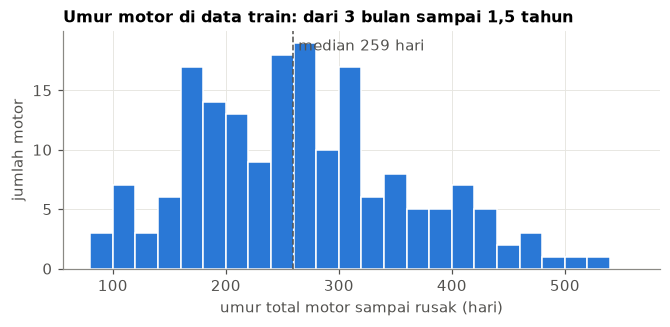

{'count': 180.0, 'mean': 266.0, 'std': 95.0, 'min': 91.0, '25%': 192.0, '50%': 259.0, '75%': 318.0, 'max': 524.0}


In [17]:
umur_total = (train["hari_operasi"] + train[TARGET]).groupby(train["motor_id"]).max()
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(umur_total, bins=np.arange(80, 561, 20), color=BIRU, edgecolor="white", linewidth=1)
ax.axvline(umur_total.median(), color=TINTA, linewidth=1, linestyle="--")
ax.text(umur_total.median() + 5, ax.get_ylim()[1] * 0.92, f"median {umur_total.median():.0f} hari", color=TINTA)
ax.set(xlabel="umur total motor sampai rusak (hari)", ylabel="jumlah motor", title="Umur motor di data train: dari 3 bulan sampai 1,5 tahun")
fig.savefig(GAMBAR / "02_umur_total.png")
plt.show()
print(umur_total.describe().round(0).to_dict())

Motor tercepat rusak dalam ±3 bulan dan yang terlama bertahan ±1,5 tahun. Artinya umur motor (`hari_operasi`)
saja tidak cukup untuk menebak RUL; model perlu tanda kerusakan dari sensor.

### 5.2 Sensor mana yang berubah menjelang rusak?

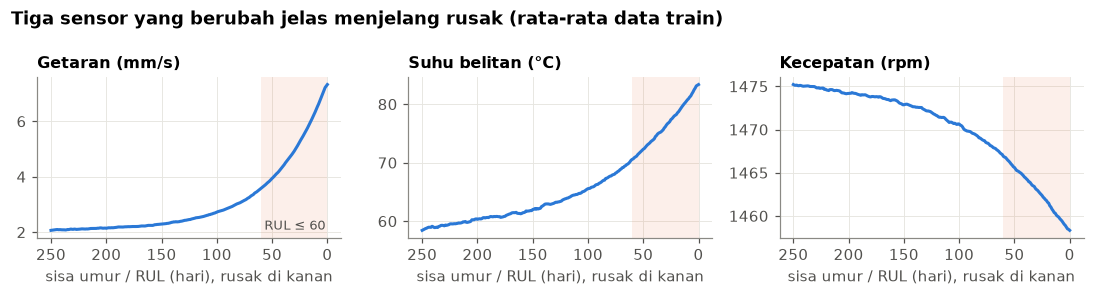

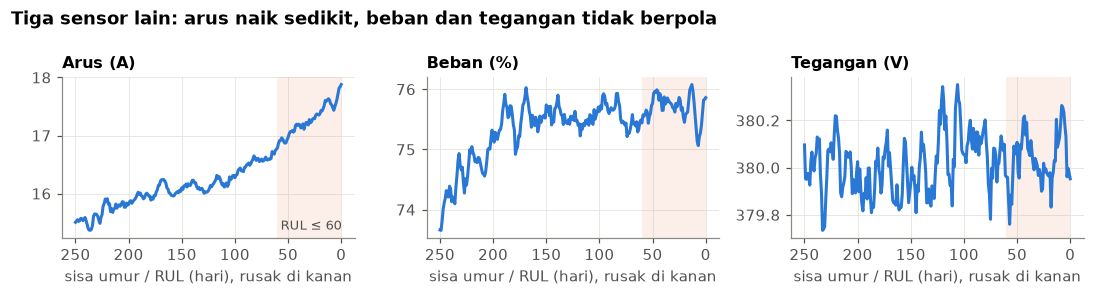

korelasi dengan RUL (semua baris | baris RUL<=60):
                  semua  RUL<=60
beban_pct         -0.07     0.00
arus_A            -0.10    -0.03
tegangan_V        -0.01    -0.01
suhu_belitan_C    -0.69    -0.57
getaran_rms_mm_s  -0.70    -0.83
kecepatan_rpm      0.73     0.64
hari_operasi      -0.57    -0.18


In [18]:
rata = train.groupby(TARGET)[KOLOM_SENSOR].mean().loc[:250]
judul = {"getaran_rms_mm_s": "Getaran (mm/s)", "suhu_belitan_C": "Suhu belitan (°C)", "kecepatan_rpm": "Kecepatan (rpm)",
         "arus_A": "Arus (A)", "beban_pct": "Beban (%)", "tegangan_V": "Tegangan (V)"}
kelompok_sensor = {
    "03a_sensor_berubah.png": ("Tiga sensor yang berubah jelas menjelang rusak (rata-rata data train)", ["getaran_rms_mm_s", "suhu_belitan_C", "kecepatan_rpm"]),
    "03b_sensor_lain.png": ("Tiga sensor lain: arus naik sedikit, beban dan tegangan tidak berpola", ["arus_A", "beban_pct", "tegangan_V"]),
}
for berkas, (judul_gambar, kolom_gambar) in kelompok_sensor.items():
    fig, axes = plt.subplots(1, 3, figsize=(10, 2.7))
    for ax, kolom in zip(axes, kolom_gambar):
        ax.plot(rata.index, rata[kolom].rolling(5, center=True, min_periods=1).mean(), color=BIRU)
        ax.axvspan(0, BATAS_DEKAT_RUSAK, color=ORANYE, alpha=0.10, linewidth=0)
        ax.invert_xaxis()  # sumbu-x dibalik: motor berjalan dari kiri (masih lama) ke kanan (rusak)
        ax.set(title=judul[kolom], xlabel="sisa umur / RUL (hari), rusak di kanan")
    batas_y = axes[0].get_ylim()
    axes[0].text(57, batas_y[0] + 0.05 * (batas_y[1] - batas_y[0]), "RUL ≤ 60", color=TINTA, fontsize=8.5)
    fig.suptitle(judul_gambar, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    fig.savefig(GAMBAR / berkas)
    plt.show()

print("korelasi dengan RUL (semua baris | baris RUL<=60):")
dekat = train[train[TARGET] <= BATAS_DEKAT_RUSAK]
print(pd.DataFrame({"semua": train[KOLOM_SENSOR + ["hari_operasi"]].corrwith(train[TARGET]),
                    "RUL<=60": dekat[KOLOM_SENSOR + ["hari_operasi"]].corrwith(dekat[TARGET])}).round(2))

- **Getaran naik**, **suhu belitan naik**, dan **kecepatan turun** menjelang rusak. Ketiganya adalah tanda kerusakan.
  Arus juga naik sedikit.
- Beban dan tegangan datar: keduanya menggambarkan kondisi kerja hari itu, bukan kesehatan motor.
- Saat RUL masih di atas ±150 hari, semua kurva hampir datar. Motor sehat yang masih punya 200 hari dan yang masih
  punya 400 hari **terlihat sama** di sensor. Jadi galat pada RUL besar pasti tinggi, model apa pun yang dipakai.
  Ini sejalan dengan fokus klien pada RUL ≤ 60.
- Kurvanya melengkung (naik makin cepat), bukan garis lurus. Ini petunjuk bahwa regresi linear akan kesulitan.

### 5.3 Beban ikut menggerakkan sensor

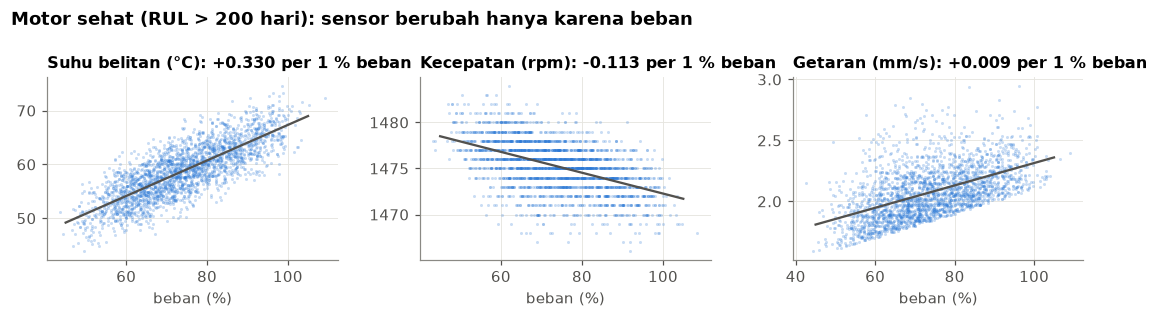

In [19]:
sehat = train[train[TARGET] > 200]   # motor yang masih jauh dari rusak
fig, axes = plt.subplots(1, 3, figsize=(10, 2.9))
kemiringan = {}
for ax, kolom in zip(axes, ["suhu_belitan_C", "kecepatan_rpm", "getaran_rms_mm_s"]):
    data = sehat[["beban_pct", kolom]].dropna()
    kemiringan[kolom], titik_potong = np.polyfit(data["beban_pct"], data[kolom], 1)
    contoh = data.sample(2500, random_state=SEED)
    ax.scatter(contoh["beban_pct"], contoh[kolom], s=4, color=BIRU, alpha=0.25, linewidths=0)
    x = np.array([45, 105])
    ax.plot(x, titik_potong + kemiringan[kolom] * x, color=TINTA, linewidth=1.5)
    ax.set(title=f"{judul[kolom]}: {kemiringan[kolom]:+.3f} per 1 % beban", xlabel="beban (%)")
fig.suptitle("Motor sehat (RUL > 200 hari): sensor berubah hanya karena beban", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(GAMBAR / "04_pengaruh_beban.png")
plt.show()

# koefisien di src/features.py harus sama dengan yang terukur di sini
assert abs(kemiringan["suhu_belitan_C"] - KOEF_SUHU) < 0.02
assert abs(kemiringan["kecepatan_rpm"] - KOEF_RPM) < 0.01
assert abs(kemiringan["getaran_rms_mm_s"] - KOEF_GETARAN) < 0.002

Pada motor yang sehat pun, suhu belitan naik ±0,33 °C dan kecepatan turun ±0,11 rpm setiap beban naik 1 %.
Jadi suhu 75 °C bisa berarti "motor mulai rusak" atau hanya "hari ini bebannya berat". Karena itu dibuat fitur
**terkoreksi beban**: nilai sensor seandainya motor bekerja pada beban acuan 75 %. Koefisiennya diambil dari
kemiringan garis di atas (motor sehat, data train saja) dan disimpan di `src/features.py`.

### 5.4 Kecepatan memburuk berbeda antara motor berumur pendek dan panjang

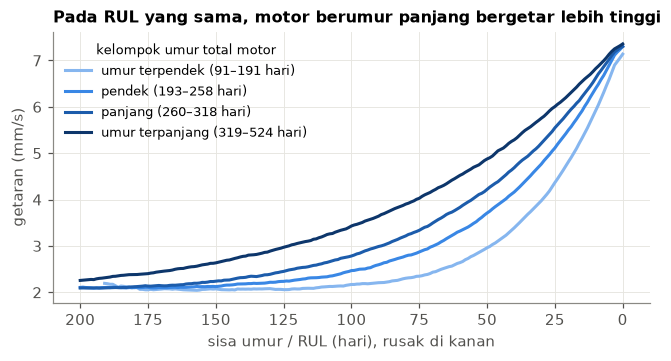

In [20]:
kelompok = pd.qcut(umur_total, 4, labels=["umur terpendek", "pendek", "panjang", "umur terpanjang"])
gabung = train.assign(kelompok=train["motor_id"].map(kelompok))
fig, ax = plt.subplots(figsize=(7, 3.2))
for warna, (nama, data) in zip(BIRU_BERTINGKAT, gabung.groupby("kelompok", observed=True)):
    kurva = data.groupby(TARGET)["getaran_rms_mm_s"].mean().loc[:200].rolling(7, center=True, min_periods=1).mean()
    ax.plot(kurva.index, kurva, color=warna, label=f"{nama} ({umur_total[kelompok == nama].min():.0f}–{umur_total[kelompok == nama].max():.0f} hari)")
ax.invert_xaxis()
ax.set(xlabel="sisa umur / RUL (hari), rusak di kanan", ylabel="getaran (mm/s)",
       title="Pada RUL yang sama, motor berumur panjang bergetar lebih tinggi")
ax.legend(title="kelompok umur total motor", fontsize=8.5, title_fontsize=8.5)
fig.savefig(GAMBAR / "05_getaran_per_umur.png")
plt.show()

Ini temuan terpenting untuk model. Pada RUL 90 hari, motor berumur terpendek masih bergetar ±2,2 mm/s (hampir
seperti motor sehat), sedangkan motor berumur terpanjang sudah ±3,7 mm/s. Kerusakan berjalan **sebanding dengan umur motornya**: motor yang berumur
panjang memburuk pelan-pelan dalam waktu lama, motor yang berumur pendek memburuk mendadak.

Akibatnya, getaran 4 mm/s bisa berarti "25 hari lagi" atau "75 hari lagi". Untuk membedakannya model perlu tahu
**sudah berapa lama motor bekerja** (`hari_operasi`). Kolom ini bukan sensor, tetapi selalu diketahui perencana
pemeliharaan (tanggal pasang motor tercatat) dan tidak membocorkan target, jadi sah dipakai sebagai masukan.

## 6. Baseline wajib: regresi linear dengan sensor asli

Sesuai brief: enam sensor asli, tanpa fitur buatan. Nilai kosong diisi median (dihitung dari data train di dalam
*pipeline*, jadi tidak mengintip validation).

In [21]:
def buat_baseline():
    return Pipeline([
        ("sensor", FunctionTransformer(sensor_asli)),
        ("isi_kosong", SimpleImputer(strategy="median")),
        ("model", LinearRegression()),
    ])


hasil_val = {}
baseline = buat_baseline().fit(train[FITUR_INPUT], train[TARGET])
tebakan_baseline_val = baseline.predict(val[FITUR_INPUT])
hasil_val["Baseline: regresi linear, sensor asli"] = nilai(val[TARGET], tebakan_baseline_val)
pd.DataFrame(hasil_val).T.round(2)

,MAE RUL≤60,MAE semua baris
"Baseline: regresi linear, sensor asli",30.91,49.59


Baseline meleset rata-rata sekitar sebulan pada motor yang sisa umurnya tinggal ≤ 60 hari. Untuk klien yang masa
tunggu pengirimannya 2–4 minggu, galat sebesar itu berarti pesanan bisa terlambat. Ini angka yang harus dilampaui.

## 7. Model lain dan perbandingan pada data validation

Langkah perbaikan dicoba satu per satu supaya jelas perbaikan mana yang menyumbang apa:

1. regresi linear + fitur buatan (apakah fitur saja cukup?),
2. *random forest* dan *gradient boosting* dengan sensor asli (apakah model non-linear saja cukup?),
3. *gradient boosting* + fitur buatan tanpa `hari_operasi`,
4. *gradient boosting* + fitur buatan + `hari_operasi`.

Fitur buatan (lihat `tambah_fitur` di `src/features.py`):

| Fitur | Rumus | Alasan |
|---|---|---|
| `daya_kW` | dari `tipe_motor` | tipe motor sebagai angka |
| `rasio_arus` | arus / (daya × beban) | arus per kW beban, bisa dibandingkan antartipe; naik saat motor memburuk |
| `slip_pct` | (1500 − rpm) / 1500 | ketertinggalan putaran dari putaran sinkron |
| `suhu_koreksi`, `rpm_koreksi`, `getaran_koreksi` | sensor − koefisien × (beban − 75) | membuang pengaruh beban (bagian 5.3) |

In [22]:
def fitur_tanpa_hari(df):
    return tambah_fitur(df).drop(columns="hari_operasi")


kandidat = {
    "Regresi linear + fitur buatan": Pipeline([("fitur", FunctionTransformer(tambah_fitur)), ("isi_kosong", SimpleImputer(strategy="median")), ("model", LinearRegression())]),
    "Random forest, sensor asli": Pipeline([("sensor", FunctionTransformer(sensor_asli)), ("isi_kosong", SimpleImputer(strategy="median")),
                                            ("model", RandomForestRegressor(n_estimators=200, min_samples_leaf=20, n_jobs=-1, random_state=SEED))]),
    "Gradient boosting, sensor asli": buat_gb(sensor_asli),
    "Gradient boosting + fitur buatan, tanpa hari_operasi": buat_gb(fitur_tanpa_hari),
    "Gradient boosting + fitur buatan + hari_operasi": buat_gb(tambah_fitur),
}
for nama, model in kandidat.items():
    model.fit(train[FITUR_INPUT], train[TARGET])
    hasil_val[nama] = nilai(val[TARGET], model.predict(val[FITUR_INPUT]))
pd.DataFrame(hasil_val).T.round(2)

,MAE RUL≤60,MAE semua baris
"Baseline: regresi linear, sensor asli",30.91,49.59
Regresi linear + fitur buatan,30.30,49.11
"Random forest, sensor asli",13.99,44.26
"Gradient boosting, sensor asli",12.65,44.26
"Gradient boosting + fitur buatan, tanpa hari_operasi",12.38,44.00
Gradient boosting + fitur buatan + hari_operasi,8.79,42.26


Yang terbaca dari tabel:

- Fitur buatan hampir tidak menolong regresi linear. Masalahnya ada pada bentuk modelnya: garis lurus tidak
  bisa mengikuti kurva kerusakan yang melengkung (EDA 5.2).
- Model pohon (*random forest*, *gradient boosting*) memotong galat lebih dari separuh hanya dengan sensor asli.
- Untuk model pohon, fitur koreksi beban hanya menambah sedikit, karena pohon bisa mempelajari sendiri hubungan
  sensor dengan beban. Fitur itu tetap dipakai: tidak merugikan, dan `rasio_arus` berguna di aplikasi untuk
  mendeteksi masukan yang tidak cocok dengan tipe motornya.
- **`hari_operasi` adalah tambahan yang paling besar pengaruhnya**, sesuai temuan EDA 5.4.

### Memberi bobot lebih pada motor yang mendekati rusak

Klien paling peduli pada RUL ≤ 60. Model bisa diarahkan ke sana dengan `sample_weight`: kesalahan pada baris
RUL ≤ 60 dihitung beberapa kali lebih mahal saat pelatihan. Bobot yang terlalu besar akan merusak tebakan untuk
motor sehat, jadi aturannya ditetapkan dulu: **pilih bobot dengan MAE RUL ≤ 60 terkecil, asalkan MAE semua baris
tidak memburuk lebih dari 0,5 hari** dibanding tanpa bobot.

In [23]:
def bobot_baris(y, bobot):
    return np.where(np.asarray(y) <= BATAS_DEKAT_RUSAK, float(bobot), 1.0)


uji_bobot = {}
for bobot in [1, 2, 3, 5, 8]:
    model = buat_gb().fit(train[FITUR_INPUT], train[TARGET], model__sample_weight=bobot_baris(train[TARGET], bobot))
    uji_bobot[bobot] = nilai(val[TARGET], model.predict(val[FITUR_INPUT]))
uji_bobot = pd.DataFrame(uji_bobot).T.rename_axis("bobot baris RUL≤60")
print(uji_bobot.round(2))

boleh = uji_bobot[uji_bobot["MAE semua baris"] <= uji_bobot.loc[1, "MAE semua baris"] + 0.5]
BOBOT = int(boleh["MAE RUL≤60"].idxmin())
print("\nbobot terpilih:", BOBOT)

                    MAE RUL≤60  MAE semua baris
bobot baris RUL≤60                             
1                         8.79            42.30
2                         7.90            42.35
3                         7.47            42.60
5                         7.22            42.96
8                         7.08            43.37

bobot terpilih: 3


In [24]:
model_val = buat_gb().fit(train[FITUR_INPUT], train[TARGET], model__sample_weight=bobot_baris(train[TARGET], BOBOT))
tebakan_val = model_val.predict(val[FITUR_INPUT])
NAMA_FINAL = f"Gradient boosting + fitur buatan + hari_operasi + bobot {BOBOT}×"
hasil_val[NAMA_FINAL] = nilai(val[TARGET], tebakan_val)

tabel_val = pd.DataFrame(hasil_val).T
tabel_val.round(2)

,MAE RUL≤60,MAE semua baris
"Baseline: regresi linear, sensor asli",30.91,49.59
Regresi linear + fitur buatan,30.30,49.11
"Random forest, sensor asli",13.99,44.26
"Gradient boosting, sensor asli",12.65,44.26
"Gradient boosting + fitur buatan, tanpa hari_operasi",12.38,44.00
Gradient boosting + fitur buatan + hari_operasi,8.79,42.26
Gradient boosting + fitur buatan + hari_operasi + bobot 3×,7.47,42.60


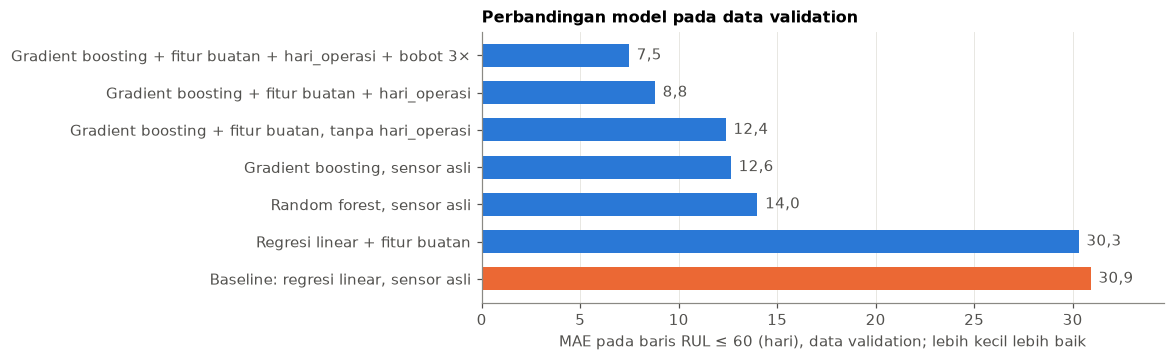

In [25]:
fig, ax = plt.subplots(figsize=(8, 3.2))
urut = tabel_val["MAE RUL≤60"].sort_values(ascending=False)
warna = [ORANYE if nama.startswith("Baseline") else BIRU for nama in urut.index]
ax.barh(urut.index, urut.values, color=warna, height=0.62)
for i, v in enumerate(urut.values):
    ax.text(v + 0.4, i, f"{v:.1f}".replace(".", ","), va="center", color=TINTA)
ax.set(xlabel="MAE pada baris RUL ≤ 60 (hari), data validation; lebih kecil lebih baik", title="Perbandingan model pada data validation")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, urut.max() * 1.12)
fig.savefig(GAMBAR / "06_perbandingan_validation.png")
plt.show()

Hiperparameter *gradient boosting* (jumlah pohon, ukuran daun) juga dicoba, tetapi hasilnya hanya bergeser ±0,2
hari, jadi dipakai nilai bawaan scikit-learn dengan 400 pohon. Model final yang dipilih adalah baris terakhir tabel.

## 8. Memilih model final dan ambang status

### 8.1 Di mana model masih keliru?

In [26]:
batas_bin = [-1, 7, 14, 28, 45, 60, 90, 150, 600]
nama_bin = ["0–7", "8–14", "15–28", "29–45", "46–60", "61–90", "91–150", ">150"]
cek_val = val.assign(tebakan=tebakan_val, tebakan_baseline=tebakan_baseline_val,
                     kelompok_rul=pd.cut(val[TARGET], batas_bin, labels=nama_bin))
galat_bin = cek_val.groupby("kelompok_rul", observed=True).apply(lambda g: pd.Series({
    "jumlah baris": len(g),
    "MAE baseline": (g["tebakan_baseline"] - g[TARGET]).abs().mean(),
    "MAE model": (g["tebakan"] - g[TARGET]).abs().mean(),
    "bias model (tebakan − asli)": (g["tebakan"] - g[TARGET]).mean(),
}), include_groups=False)
galat_bin.round(1)

,jumlah baris,MAE baseline,MAE model,bias model (tebakan − asli)
kelompok_rul,,,,
0–7,472.0,27.9,1.7,0.7
8–14,414.0,22.8,3.0,0.8
15–28,823.0,25.3,5.3,1.9
29–45,1010.0,32.4,8.6,3.2
46–60,881.0,39.9,13.3,3.7
61–90,1772.0,48.2,29.0,12.0
91–150,3459.0,49.9,45.8,23.8
>150,7424.0,58.8,61.4,-41.7


Makin dekat ke rusak, makin tepat tebakannya: beberapa hari saja pada dua minggu terakhir. Di atas 150 hari model
praktis hanya bisa berkata "masih lama" (lihat EDA 5.2). Bias positif pada 29–60 hari berarti model cenderung
sedikit **terlalu optimistis** di rentang itu, dan ini harus diperhitungkan saat menentukan ambang status.

### 8.2 Ambang status

Aplikasi harus mengeluarkan satu dari tiga status. Ambangnya diturunkan dari kebutuhan klien dan dipilih dengan
data validation, bukan ditebak:

- **PESAN PENGGANTI SEKARANG**: pengiriman paling lama 4 minggu, jadi alarm harus muncul saat sisa umur
  sebenarnya masih ≥ 28 hari. Dipilih ambang terkecil (kelipatan 5 hari) yang membuat **≥ 95 % motor validation**
  mendapat alarm pertama setidaknya 28 hari sebelum rusak.
- **SEGERA GANTI**: pengiriman tercepat 2 minggu. Kalau sisa umur ≤ 14 hari, memesan saja sudah tidak cukup;
  motor harus diganti dengan stok cadangan atau pengiriman kilat. Dipilih ambang terkecil yang menangkap
  **≥ 95 % baris validation dengan RUL ≤ 14**.
- **AMAN**: selain itu.

In [27]:
def rul_saat_alarm_pertama(data, tebakan, ambang):
    """Untuk tiap motor: sisa umur SEBENARNYA pada hari pertama tebakan <= ambang (0 kalau alarm tidak pernah muncul)."""
    kena_alarm = data[np.asarray(tebakan) <= ambang]
    # hari paling awal = RUL sebenarnya paling besar di antara baris yang kena alarm
    return kena_alarm.groupby("motor_id")[TARGET].max().reindex(data["motor_id"].unique(), fill_value=0)


baris = []
for ambang in range(30, 75, 5):
    jarak = rul_saat_alarm_pertama(val, tebakan_val, ambang)
    baris.append({"ambang pesan (hari)": ambang,
                  "motor dengan alarm ≥ 28 hari sebelum rusak": (jarak >= 28).mean(),
                  "median sisa umur saat alarm pertama": jarak.median(),
                  "alarm paling dini (hari sebelum rusak)": jarak.max(),
                  "baris RUL>90 yang ikut kena alarm": ((tebakan_val <= ambang) & (val[TARGET] > 90)).sum() / (val[TARGET] > 90).sum()})
uji_pesan = pd.DataFrame(baris).set_index("ambang pesan (hari)")
print(uji_pesan.round(3))
AMBANG_PESAN = int(uji_pesan[uji_pesan["motor dengan alarm ≥ 28 hari sebelum rusak"] >= 0.95].index.min())

sangat_dekat = val[TARGET] <= 14
uji_segera = pd.DataFrame([{"ambang segera (hari)": a,
                            "baris RUL≤14 yang tertangkap": (tebakan_val[sangat_dekat] <= a).mean(),
                            "baris berstatus segera padahal RUL>28": ((tebakan_val <= a) & (val[TARGET] > 28)).sum() / max((tebakan_val <= a).sum(), 1)}
                           for a in range(10, 27, 2)]).set_index("ambang segera (hari)")
print()
print(uji_segera.round(3))
AMBANG_SEGERA = int(uji_segera[uji_segera["baris RUL≤14 yang tertangkap"] >= 0.95].index.min())

print(f"\nAMBANG_PESAN = {AMBANG_PESAN} hari | AMBANG_SEGERA = {AMBANG_SEGERA} hari")

                     motor dengan alarm ≥ 28 hari sebelum rusak  median sisa umur saat alarm pertama  alarm paling dini (hari sebelum rusak)  baris RUL>90 yang ikut kena alarm
ambang pesan (hari)                                                                                                                                                            
30                                                        0.650                                 30.0                                      59                              0.000
35                                                        0.833                                 35.0                                      69                              0.000
40                                                        0.933                                 40.5                                      70                              0.000
45                                                        1.000                                 48.5                    

Ambang pesan lebih besar daripada 28 hari karena dua hal: model sedikit optimistis di rentang 29–60 hari, dan
tebakan harian naik-turun mengikuti derau sensor. Selisihnya adalah **margin keamanan** yang diukur dari data.
Harganya: pesanan dibuat lebih awal daripada yang benar-benar perlu (lihat kolom median), tetapi itu jauh lebih
murah daripada lini produksi berhenti karena motor rusak sebelum penggantinya tiba.

In [28]:
def status_dari_rul(rul):
    if rul <= AMBANG_SEGERA:
        return "SEGERA GANTI"
    if rul <= AMBANG_PESAN:
        return "PESAN PENGGANTI SEKARANG"
    return "AMAN"


urutan_status = ["SEGERA GANTI", "PESAN PENGGANTI SEKARANG", "AMAN"]
kondisi_asli = pd.cut(val[TARGET], [-1, 14, 28, 60, 600], labels=["RUL 0–14", "RUL 15–28", "RUL 29–60", "RUL > 60"])
status_val = pd.Series([status_dari_rul(r) for r in tebakan_val], index=val.index)
print("Status yang keluar untuk tiap kondisi sebenarnya (validation, proporsi per baris):")
pd.crosstab(kondisi_asli, status_val, normalize="index")[urutan_status].round(3)

Status yang keluar untuk tiap kondisi sebenarnya (validation, proporsi per baris):


col_0,SEGERA GANTI,PESAN PENGGANTI SEKARANG,AMAN
rul_hari,,,
RUL 0–14,0.959,0.041,0.000
RUL 15–28,0.266,0.725,0.009
RUL 29–60,0.006,0.506,0.488
RUL > 60,0.000,0.007,0.993


### 8.3 Kisaran galat untuk ditampilkan di aplikasi

Satu angka RUL tanpa keterangan bisa menyesatkan. Aplikasi akan menampilkan juga **kisaran 80 %**: untuk tiap
rentang tebakan, diambil persentil ke-10 dan ke-90 dari selisih (RUL asli − tebakan) pada data validation.

In [29]:
batas_tebakan = [14, 28, 45, 60, 90, 150, 10_000]
kelompok_tebakan = pd.cut(tebakan_val, [-np.inf] + batas_tebakan, labels=batas_tebakan)
selisih = pd.Series(val[TARGET].to_numpy() - tebakan_val)
kisaran = selisih.groupby(np.asarray(kelompok_tebakan)).quantile([0.1, 0.9]).unstack()
KISARAN_GALAT = [{"tebakan_maks": int(b), "bawah": round(float(kisaran.loc[b, 0.1]), 1), "atas": round(float(kisaran.loc[b, 0.9]), 1)} for b in batas_tebakan]
pd.DataFrame(KISARAN_GALAT)

,tebakan_maks,bawah,atas
0,14,-2.8,5.0
1,28,-6.0,9.8
2,45,-10.1,19.9
3,60,-10.3,35.9
4,90,-16.0,52.6
5,150,-35.4,75.6
6,10000,-87.5,130.8


### 8.4 Masukan mana yang paling berpengaruh?

*Permutation importance*: satu kolom masukan diacak, lalu diukur berapa hari MAE RUL ≤ 60 memburuk. Makin besar
pemburukannya, makin bergantung model pada kolom itu. Dihitung pada data validation.

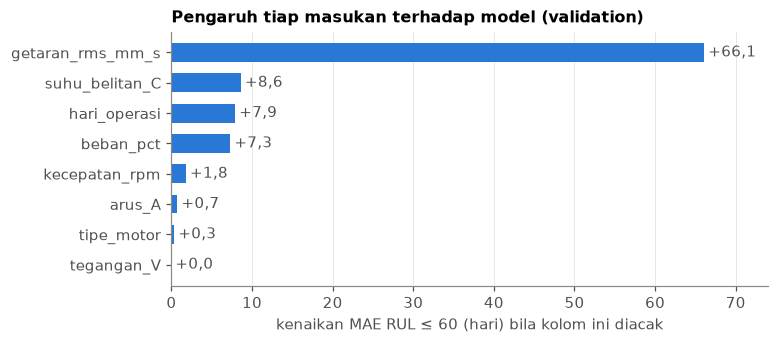

In [30]:
def skor_mae_dekat_rusak(model, X, y):
    return -nilai(y, model.predict(X))["MAE RUL≤60"]


penting = permutation_importance(model_val, val[FITUR_INPUT], val[TARGET], scoring=skor_mae_dekat_rusak, n_repeats=5, random_state=SEED)
penting = pd.Series(penting.importances_mean, index=FITUR_INPUT).sort_values()

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(penting.index, penting.values, color=BIRU, height=0.62)
for i, v in enumerate(penting.values):
    ax.text(v + 0.5, i, f"+{max(v, 0):.1f}".replace(".", ","), va="center", color=TINTA)
ax.set(xlabel="kenaikan MAE RUL ≤ 60 (hari) bila kolom ini diacak", title="Pengaruh tiap masukan terhadap model (validation)")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, penting.max() * 1.12)
fig.savefig(GAMBAR / "07_pengaruh_fitur.png")
plt.show()

Urutannya masuk akal secara fisik. **Getaran** jauh di atas yang lain karena merupakan tanda kerusakan mekanis
yang paling jelas (EDA 5.2). Berikutnya **suhu belitan**, **`hari_operasi`** (konteks cepat-lambatnya kerusakan,
EDA 5.4), dan **beban**. Beban sendiri tidak berkaitan dengan RUL, tetapi model membutuhkannya untuk menafsirkan
suhu dan kecepatan (EDA 5.3), jadi mengacaknya ikut merusak tebakan. Tegangan tidak berpengaruh, sesuai EDA 5.2.

## 9. Eksperimen tambahan: memakai riwayat beberapa hari

Brief meminta tebakan dari sensor **hari ini**, dan itulah model final. Sebagai bahan "langkah berikutnya", dicoba
seberapa besar perbaikan kalau model juga diberi **riwayat**: rata-rata sensor 7 hari terakhir (derau harian
teredam) dan tren getaran (rata-rata 7 hari dikurangi rata-rata 28 hari, yaitu seberapa cepat motor memburuk).
Eksperimen ini hanya memakai train dan validation.

In [31]:
def tambah_riwayat(df):
    """Fitur model + riwayat per motor. Butuh data beberapa hari, jadi belum bisa dipakai di aplikasi sekarang."""
    X = tambah_fitur(df)
    per_motor = df["motor_id"]
    for kolom in ["getaran_koreksi", "suhu_koreksi", "rpm_koreksi", "rasio_arus"]:
        X[kolom + "_7hari"] = X[kolom].groupby(per_motor).transform(lambda s: s.rolling(7, min_periods=1).mean())
    rata_28hari = X["getaran_koreksi"].groupby(per_motor).transform(lambda s: s.rolling(28, min_periods=1).mean())
    X["tren_getaran"] = X["getaran_koreksi_7hari"] - rata_28hari
    return X


gb_riwayat = HistGradientBoostingRegressor(loss="absolute_error", learning_rate=0.05, max_iter=400, random_state=SEED)
gb_riwayat.fit(tambah_riwayat(train), train[TARGET], sample_weight=bobot_baris(train[TARGET], BOBOT))
hasil_riwayat = nilai(val[TARGET], gb_riwayat.predict(tambah_riwayat(val)))
pd.DataFrame({NAMA_FINAL + " (satu hari)": hasil_val[NAMA_FINAL], "Sama, ditambah riwayat (rata-rata 7 hari + tren getaran)": hasil_riwayat}).T.round(2)

,MAE RUL≤60,MAE semua baris
Gradient boosting + fitur buatan + hari_operasi + bobot 3× (satu hari),7.47,42.60
"Sama, ditambah riwayat (rata-rata 7 hari + tren getaran)",4.56,38.29


Dengan riwayat, galat pada RUL ≤ 60 turun lagi sekitar sepertiga. Tren getaran menjawab pertanyaan yang tidak bisa
dijawab pembacaan satu hari: motor ini memburuk cepat atau lambat (EDA 5.4)? Model ini belum dipakai karena
mengubah cara pakai aplikasi (perencana harus mengunggah pembacaan ±4 minggu, bukan sehari) dan itu di luar
permintaan brief, tetapi ini kandidat terkuat untuk versi berikutnya.

## 10. Model final dan data test (dibuka satu kali)

Semua keputusan sudah diambil dengan data validation: jenis model, fitur, bobot, dan ambang status. Sekarang
model final dilatih ulang dengan train + validation (240 motor), lalu data test dibuka **satu kali**. Baseline
juga dilatih ulang dengan data yang sama supaya perbandingannya adil. Setelah sel ini, tidak ada yang diubah lagi.

In [32]:
trainval = pd.concat([train, val])
model_final = buat_gb().fit(trainval[FITUR_INPUT], trainval[TARGET], model__sample_weight=bobot_baris(trainval[TARGET], BOBOT))
baseline_final = buat_baseline().fit(trainval[FITUR_INPUT], trainval[TARGET])

test = bersih[bersih["motor_id"].isin(id_test)]          # <- data test dibuka di sini
tebakan_test = model_final.predict(test[FITUR_INPUT])
tebakan_baseline_test = baseline_final.predict(test[FITUR_INPUT])

hasil_test = {"Baseline: regresi linear, sensor asli": nilai(test[TARGET], tebakan_baseline_test), NAMA_FINAL: nilai(test[TARGET], tebakan_test)}
ringkas = pd.concat({"validation": tabel_val.loc[list(hasil_test)], "test": pd.DataFrame(hasil_test).T}, axis=1)
print(f"test: {test['motor_id'].nunique()} motor, {len(test):,} baris, {int((test[TARGET] <= BATAS_DEKAT_RUSAK).sum()):,} baris RUL<=60")
ringkas.round(2)

test: 60 motor, 15,487 baris, 3,610 baris RUL<=60


validation                       test                
                                                   MAE RUL≤60 MAE semua baris MAE RUL≤60 MAE semua baris
Baseline: regresi linear, sensor asli                   30.91           49.59      30.87           49.05
Gradient boosting + fitur buatan + hari_operasi...       7.47           42.60       6.84           39.82

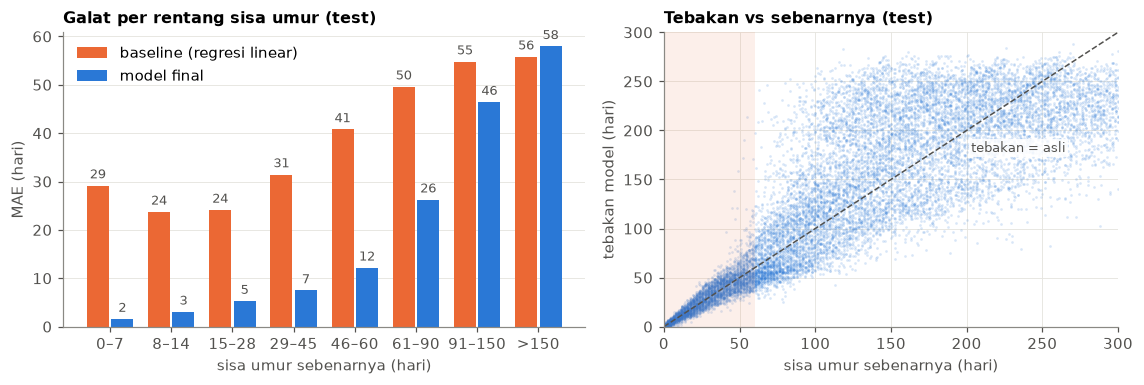

,MAE baseline,MAE model
kelompok_rul,,
0–7,29.2,1.6
8–14,23.7,3.0
15–28,24.1,5.3
29–45,31.4,7.5
46–60,40.8,12.2
61–90,49.6,26.2
91–150,54.8,46.4
>150,55.8,57.9


In [33]:
cek_test = test.assign(tebakan=tebakan_test, tebakan_baseline=tebakan_baseline_test,
                       kelompok_rul=pd.cut(test[TARGET], batas_bin, labels=nama_bin))
galat_test = cek_test.groupby("kelompok_rul", observed=True).apply(lambda g: pd.Series({
    "MAE baseline": (g["tebakan_baseline"] - g[TARGET]).abs().mean(),
    "MAE model": (g["tebakan"] - g[TARGET]).abs().mean(),
}), include_groups=False)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
x = np.arange(len(galat_test))
ax.bar(x - 0.2, galat_test["MAE baseline"], width=0.36, color=ORANYE, label="baseline (regresi linear)")
ax.bar(x + 0.2, galat_test["MAE model"], width=0.36, color=BIRU, label="model final")
for i, v in enumerate(galat_test["MAE model"]):
    ax.text(i + 0.2, v + 1.5, f"{v:.0f}", ha="center", color=TINTA, fontsize=8.5)
for i, v in enumerate(galat_test["MAE baseline"]):
    ax.text(i - 0.2, v + 1.5, f"{v:.0f}", ha="center", color=TINTA, fontsize=8.5)
ax.set_xticks(x, galat_test.index)
ax.set(xlabel="sisa umur sebenarnya (hari)", ylabel="MAE (hari)", title="Galat per rentang sisa umur (test)")
ax.grid(axis="x", visible=False)
ax.legend()

ax = axes[1]
ax.scatter(cek_test[TARGET], cek_test["tebakan"], s=3, color=BIRU, alpha=0.18, linewidths=0)
ax.plot([0, 300], [0, 300], color=TINTA, linewidth=1, linestyle="--")
ax.text(203, 178, "tebakan = asli", color=TINTA, fontsize=8.5, bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85, "pad": 1.5})
ax.axvspan(0, BATAS_DEKAT_RUSAK, color=ORANYE, alpha=0.10, linewidth=0)
ax.set(xlim=(0, 300), ylim=(0, 300), xlabel="sisa umur sebenarnya (hari)", ylabel="tebakan model (hari)", title="Tebakan vs sebenarnya (test)")
fig.tight_layout()
fig.savefig(GAMBAR / "08_hasil_test.png")
plt.show()
galat_test.round(1)

Titik-titik menempel pada garis diagonal di daerah RUL ≤ 60 (bidang berwarna) dan melebar di atas ±100 hari,
sama seperti pola di validation. Hasil test dekat dengan hasil validation, jadi tidak ada tanda model terlalu
menyesuaikan diri dengan data validation.

### Dari sudut pandang klien: apakah pesanan akan tepat waktu?

In [34]:
jarak_test = rul_saat_alarm_pertama(test, tebakan_test, AMBANG_PESAN)
jarak_baseline = rul_saat_alarm_pertama(test, tebakan_baseline_test, AMBANG_PESAN)
operasional = pd.DataFrame({
    "motor dengan alarm ≥ 28 hari sebelum rusak": [(jarak_baseline >= 28).mean(), (jarak_test >= 28).mean()],
    "motor dengan alarm ≥ 14 hari sebelum rusak": [(jarak_baseline >= 14).mean(), (jarak_test >= 14).mean()],
    "median sisa umur saat alarm pertama (hari)": [jarak_baseline.median(), jarak_test.median()],
    "alarm paling dini (hari sebelum rusak)": [jarak_baseline.max(), jarak_test.max()],
}, index=["baseline", "model final"])
status_test = pd.Series([status_dari_rul(r) for r in tebakan_test], index=test.index)
kondisi_test = pd.cut(test[TARGET], [-1, 14, 28, 60, 600], labels=["RUL 0–14", "RUL 15–28", "RUL 29–60", "RUL > 60"])
print(operasional.round(2).T)
print("\nStatus per kondisi sebenarnya (test, proporsi per baris):")
pd.crosstab(kondisi_test, status_test, normalize="index")[urutan_status].round(3)

                                            baseline  model final
motor dengan alarm ≥ 28 hari sebelum rusak      0.93          1.0
motor dengan alarm ≥ 14 hari sebelum rusak      1.00          1.0
median sisa umur saat alarm pertama (hari)     46.50         48.5
alarm paling dini (hari sebelum rusak)        131.00        113.0

Status per kondisi sebenarnya (test, proporsi per baris):


col_0,SEGERA GANTI,PESAN PENGGANTI SEKARANG,AMAN
rul_hari,,,
RUL 0–14,0.958,0.042,0.000
RUL 15–28,0.280,0.718,0.002
RUL 29–60,0.004,0.536,0.460
RUL > 60,0.000,0.006,0.994


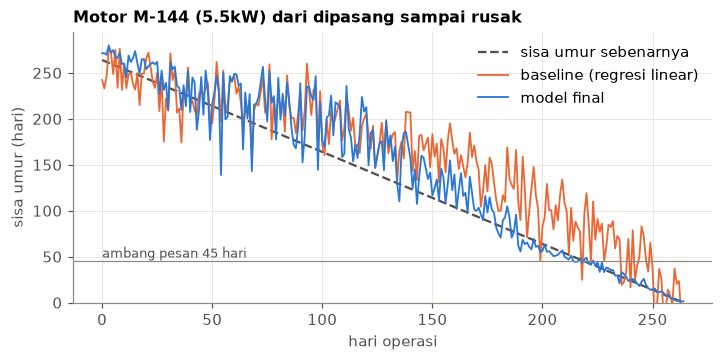

In [35]:
# contoh satu motor test dari hari pertama sampai rusak
contoh_id = jarak_test.sort_values().index[len(jarak_test) // 2]
m = cek_test[cek_test["motor_id"] == contoh_id]
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(m["hari_operasi"], m[TARGET], color=TINTA, linewidth=1.5, linestyle="--", label="sisa umur sebenarnya")
ax.plot(m["hari_operasi"], m["tebakan_baseline"], color=ORANYE, linewidth=1.2, label="baseline (regresi linear)")
ax.plot(m["hari_operasi"], m["tebakan"], color=BIRU, linewidth=1.2, label="model final")
ax.axhline(AMBANG_PESAN, color=ABU, linewidth=0.8)
ax.text(m["hari_operasi"].min(), AMBANG_PESAN + 4, f"ambang pesan {AMBANG_PESAN} hari", color=TINTA, fontsize=8.5)
ax.set(xlabel="hari operasi", ylabel="sisa umur (hari)", ylim=(0, None), title=f"Motor {contoh_id} ({m['tipe_motor'].iloc[0]}) dari dipasang sampai rusak")
ax.legend()
fig.savefig(GAMBAR / "09_contoh_motor.png")
plt.show()

Gambar ini merangkum sifat model: selama motor sehat, tebakan mendatar di sekitar "masih lama" (model tidak tahu
kapan kerusakan akan mulai). Begitu tanda kerusakan muncul di sensor, tebakan turun dan mengikuti garis
sebenarnya sampai motor rusak. Baseline bereaksi terlambat dan tetap meleset jauh di hari-hari terakhir.

## 11. Menyimpan artifact

`model.joblib` berisi *pipeline* lengkap (pembuat fitur + model), jadi aplikasi cukup memberi kolom masukan
mentah. `metadata.json` mencatat versi, fitur, ambang status, metrik, dan versi pustaka.

In [36]:
ARTIFACT = ROOT / "artifacts"
ARTIFACT.mkdir(exist_ok=True)
joblib.dump(model_final, ARTIFACT / "model.joblib")

angka = trainval[["hari_operasi"] + KOLOM_SENSOR]
metadata = {
    "versi_model": "1.0.0",
    "dibuat": date.today().isoformat(),
    "kasus": "03 - Sisa umur pakai motor induksi",
    "algoritma": "HistGradientBoostingRegressor (loss=absolute_error, 400 pohon) + fitur dari src/features.py",
    "fitur_input": FITUR_INPUT,
    "fitur_model": FITUR_MODEL,
    "target": TARGET,
    "ambang_status": {"segera_ganti_maks_hari": AMBANG_SEGERA, "pesan_pengganti_maks_hari": AMBANG_PESAN},
    "alasan_ambang": "pesan: >=95% motor validation mendapat alarm >=28 hari sebelum rusak; segera: >=95% baris validation RUL<=14 tertangkap",
    "bobot_baris_rul_le_60": BOBOT,
    "pembagian_data": {"cara": "per motor_id, proporsi tipe dijaga", "seed": SEED, "motor_train": len(id_train), "motor_validation": len(id_val), "motor_test": len(id_test)},
    "metrik_validasi": {"baseline": {k: round(v, 2) for k, v in hasil_val["Baseline: regresi linear, sensor asli"].items()},
                        "model": {k: round(v, 2) for k, v in hasil_val[NAMA_FINAL].items()}},
    "metrik_test": {"baseline": {k: round(v, 2) for k, v in hasil_test["Baseline: regresi linear, sensor asli"].items()},
                    "model": {k: round(v, 2) for k, v in hasil_test[NAMA_FINAL].items()}},
    "kisaran_galat_80persen": KISARAN_GALAT,
    "rentang_data_latih": {k: [round(float(angka[k].min()), 2), round(float(angka[k].max()), 2)] for k in angka.columns},
    "versi_library": {"python": platform.python_version(), "sklearn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__, "joblib": joblib.__version__},
}
(ARTIFACT / "metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False))
print(json.dumps(metadata, indent=2, ensure_ascii=False))

{
  "versi_model": "1.0.0",
  "dibuat": "2026-11-19",
  "kasus": "03 - Sisa umur pakai motor induksi",
  "algoritma": "HistGradientBoostingRegressor (loss=absolute_error, 400 pohon) + fitur dari src/features.py",
  "fitur_input": [
    "tipe_motor",
    "hari_operasi",
    "beban_pct",
    "arus_A",
    "tegangan_V",
    "suhu_belitan_C",
    "getaran_rms_mm_s",
    "kecepatan_rpm"
  ],
  "fitur_model": [
    "hari_operasi",
    "daya_kW",
    "beban_pct",
    "arus_A",
    "tegangan_V",
    "suhu_belitan_C",
    "getaran_rms_mm_s",
    "kecepatan_rpm",
    "rasio_arus",
    "slip_pct",
    "suhu_koreksi",
    "rpm_koreksi",
    "getaran_koreksi"
  ],
  "target": "rul_hari",
  "ambang_status": {
    "segera_ganti_maks_hari": 18,
    "pesan_pengganti_maks_hari": 45
  },
  "alasan_ambang": "pesan: >=95% motor validation mendapat alarm >=28 hari sebelum rusak; segera: >=95% baris validation RUL<=14 tertangkap",
  "bobot_baris_rul_le_60": 3,
  "pembagian_data": {
    "cara": "per motor_id,

### Uji muat ulang
Model dimuat kembali dari berkas dan harus memberi tebakan yang sama persis. Model juga harus tetap menjawab
untuk masukan yang "kotor": tipe ditulis tidak baku, suhu dalam kelvin, dan sensor kosong.

In [37]:
model_muat = joblib.load(ARTIFACT / "model.joblib")
assert np.allclose(model_muat.predict(test[FITUR_INPUT]), tebakan_test)

contoh = test[test[TARGET] == 20].iloc[[0]][FITUR_INPUT]
kotor = contoh.assign(tipe_motor=contoh["tipe_motor"].str.upper(), suhu_belitan_C=contoh["suhu_belitan_C"] + 273.15)
kosong = contoh.assign(arus_A=np.nan, getaran_rms_mm_s=-1.0)
print("RUL sebenarnya 20 hari")
print("masukan bersih            ->", round(float(model_muat.predict(contoh)[0]), 1))
print("tipe 'KW' + suhu kelvin   ->", round(float(model_muat.predict(kotor)[0]), 1))
print("arus kosong + getaran -1  ->", round(float(model_muat.predict(kosong)[0]), 1))
assert np.isclose(model_muat.predict(contoh)[0], model_muat.predict(kotor)[0])

RUL sebenarnya 20 hari
masukan bersih            -> 15.8
tipe 'KW' + suhu kelvin   -> 15.8
arus kosong + getaran -1  -> 34.1


In [38]:
# contoh berkas untuk fitur unggah CSV di aplikasi: 8 motor test pada berbagai sisa umur
tipe_test = test.groupby("motor_id")["tipe_motor"].first()
motor_contoh = [tipe_test[tipe_test == t].index[i] for i in range(3) for t in ["5.5kW", "11kW", "22kW"]][:8]   # tipe bergantian
pilih = pd.concat([test[(test["motor_id"] == mid) & (test[TARGET] <= r)].head(1) for mid, r in zip(motor_contoh, [240, 150, 90, 60, 40, 25, 12, 3])])
contoh_batch = pilih[["motor_id"] + FITUR_INPUT].reset_index(drop=True)
contoh_batch.loc[2, "suhu_belitan_C"] = round(contoh_batch.loc[2, "suhu_belitan_C"] + 273.15, 1)   # satu baris kelvin
contoh_batch.loc[5, "arus_A"] = np.nan                                                                # satu sensor kosong
contoh_batch.to_csv(ROOT / "data" / "contoh_batch.csv", index=False)
contoh_batch.assign(rul_sebenarnya=pilih[TARGET].to_numpy(), tebakan=model_muat.predict(contoh_batch[FITUR_INPUT]).round(1))

,motor_id,tipe_motor,hari_operasi,beban_pct,arus_A,tegangan_V,suhu_belitan_C,getaran_rms_mm_s,kecepatan_rpm,rul_sebenarnya,tebakan
0,M-007,5.5kW,29,81.2,8.51,364.0,64.30,1.91,1474.0,240,233.0
1,M-004,11kW,240,60.9,13.28,385.5,58.45,2.41,1471.0,150,143.4
2,M-021,22kW,138,68.6,28.81,383.4,335.40,2.24,1472.0,90,133.1
3,M-017,5.5kW,368,59.8,6.57,381.5,73.20,4.21,1468.0,60,68.2
4,M-005,11kW,185,72.7,16.34,377.8,67.40,3.52,1469.0,40,57.0
5,M-033,22kW,309,90.1,NaN,386.3,83.70,6.15,1458.0,25,22.0
6,M-020,5.5kW,313,89.2,10.36,378.2,80.20,6.83,1458.0,12,11.3
7,M-031,11kW,145,66.3,15.40,381.6,78.90,7.05,1461.0,3,2.2


## Ringkasan

- Data mentah punya delapan jenis masalah; yang paling berbahaya adalah `motor_id` yang salah tulis (bisa
  membocorkan motor antara train dan test) dan suhu Plant Purwakarta yang ternyata dalam kelvin.
- Baseline regresi linear dilampaui jauh pada kedua metrik (lihat tabel bagian 10).
- Model final: *gradient boosting* dengan fitur terkoreksi beban, `hari_operasi`, dan bobot lebih untuk baris RUL ≤ 60.
- Keterbatasan utama: selama motor masih sehat (RUL di atas ±150 hari) sensor belum memberi tanda apa pun,
  sehingga model hanya bisa berkata "masih lama". Model berguna justru pada dua bulan terakhir, saat keputusan
  pemesanan diambil.